In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from experiments_utils import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

ics_quadratic


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

In [ ]:
def plot_error_with_log_log_fit(
    df,
    error_col1,
    error_col2,
    title1,
    title2,
    error_metric_col="ERROR_METRIC",
    skip_first_n=0,
):
    # drop rows where error_col1 or error_col2 is  or zero
    df = df[(df[error_col1] > 0) & (df[error_col2] > 0)]
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
        plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()


def plot_percentage_metrics(df):
    plt.figure(figsize=(24, 7))
    plt.subplot(1, 3, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_out",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ out (perct_out)")
    plt.title(r"$\%$ out vs Number of Cluster")
    plt.ylim(0, 100)
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_good",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Good (perct_in_good)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Good vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 3)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_bad",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Bad vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

# Problems

In [ ]:
prob_dir = ICS26_DIR / "ics_quadratic"
csv_path = prob_dir / "summary.csv"

df_problem = pd.read_csv(csv_path)
df_problem = df_problem.dropna(subset=["n_clusters"])

In [ ]:
df_problem.columns

Index(['problem_name', 'problem_tag', 'tol', 'dim', 'f_dim', 'n_train',
       'n_test', 'n_clusters', 'ptwise_max_rel_error_linf',
       'ptwise_median_rel_error_linf', 'l2_relative_error', 'l2_abs_error',
       'out_l2_relative_error', 'out_l2_abs_error',
       'out_ptwise_max_rel_error_linf', 'out_ptwise_median_rel_error_linf',
       'n_out', 'perct_out', 'n_in', 'n_in_good', 'perct_in_good', 'n_in_bad',
       'perct_in_bad', 'train_time_sec', 'predict_time_sec', 'error_tag',
       'num_levels', 'N_INIT_CLUSTERS', 'N_MIN_PER_CLUSTER', 'K_NEIGHBOURS',
       'CLUSTERING_VERSION', 'USE_HESSIAN_INFORMED_SPLIT', 'ERROR_METRIC'],
      dtype='object')

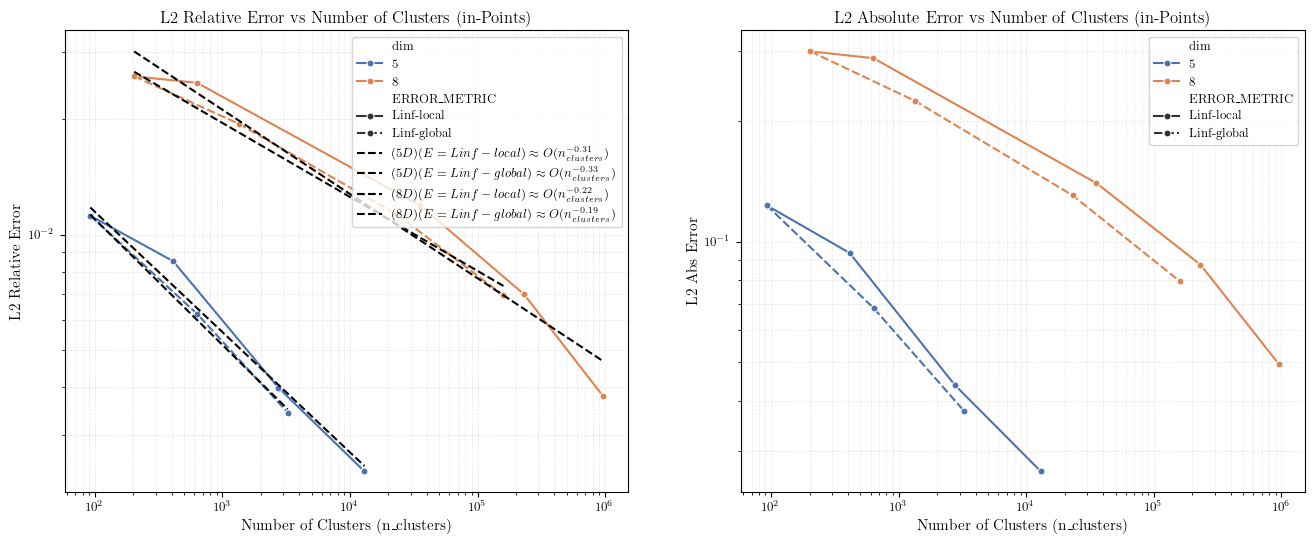

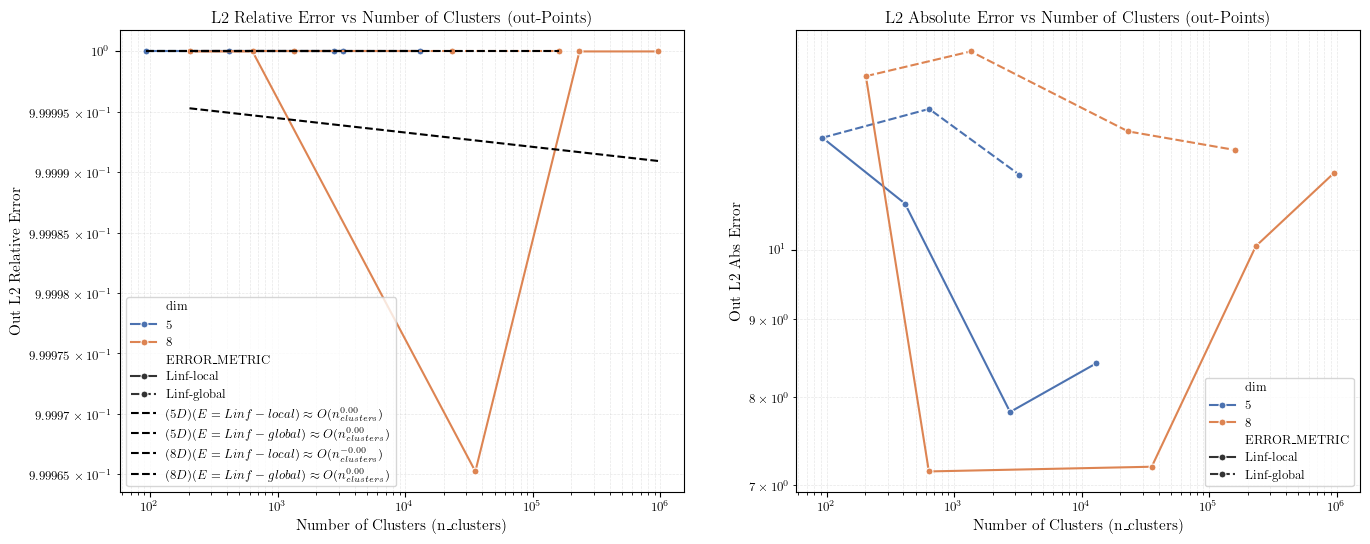

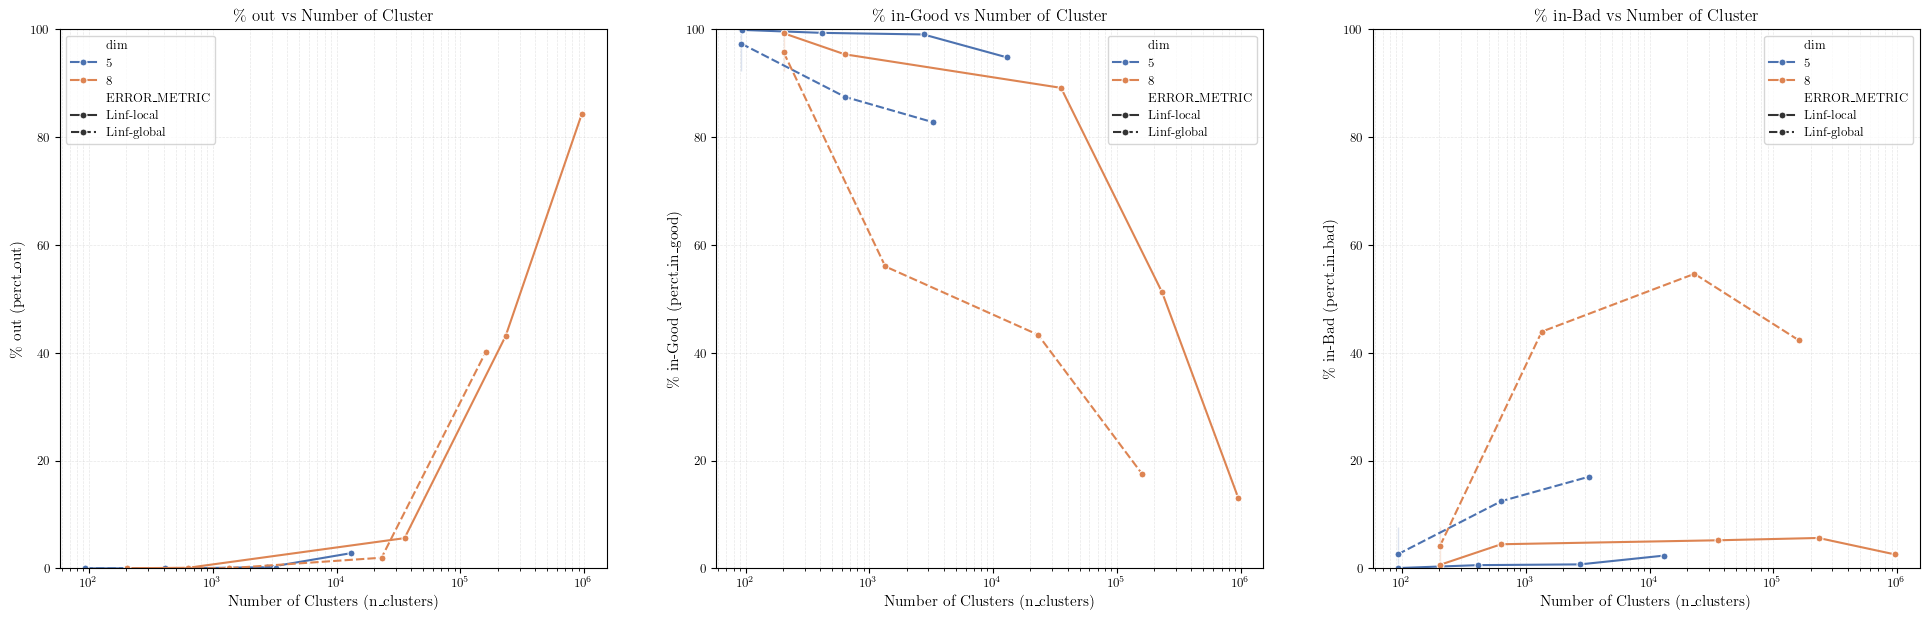

In [ ]:
if "hessian_estimation" in prob_dir.name:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_rel_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters",
        "L2 Absolute Error vs Number of Clusters",
        error_metric_col="metric",
        skip_first_n=1,
    )
else:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_relative_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters (in-Points)",
        "L2 Absolute Error vs Number of Clusters (in-Points)",
    )
    plot_error_with_log_log_fit(
        df_problem,
        "out_l2_relative_error",
        "out_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (out-Points)",
        "L2 Absolute Error vs Number of Clusters (out-Points)",
    )
    plot_percentage_metrics(df_problem)

In [68]:
def get_renamed_df(df):
    rename_cols = {
        "dim": "D",
        "f_dim": "F Dim",
        "tol": "tol",
        "ERROR_METRIC": "Error Metric",
        "n_clusters": "N Src",
        "l2_relative_error": "L2 Rel Err (In)",
        "l2_abs_error": "L2 Abs Err (In)",
        "ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (In)",
        "ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (In)",
        "out_l2_relative_error": "L2 Rel Err (Out)",
        "out_l2_abs_error": "L2 Abs Err (Out)",
        "out_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (Out)",
        "out_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (Out)",
        "perct_out": "% Out",
        "perct_in_good": "% In-Good",
        "perct_in_bad": "% In-Bad",
        "n_train": "N Train",
        "n_test": "N Test",
        "N_INIT_CLUSTERS": "Init Clusters",
        "N_MIN_PER_CLUSTER": "Min Per Cluster",
    }
    df_renamed = df.rename(columns=rename_cols)[list(rename_cols.values())]
    return df_renamed


# if "hessian_estimation" in prob_dir.name:
display(get_renamed_df(df_problem))
# get_renamed_df(df_problem).to_clipboard(index=False)

,D,F Dim,tol,Error Metric,N Src,L2 Rel Err (In),L2 Abs Err (In),Ptwise Max Rel L-inf Err (In),Ptwise Median Rel L-inf Err (In),L2 Rel Err (Out),L2 Abs Err (Out),Ptwise Max Rel L-inf Err (Out),Ptwise Median Rel L-inf Err (Out),% Out,% In-Good,% In-Bad,N Train,N Test,Init Clusters,Min Per Cluster
0,5,1,0.100,Linf-local,92,0.011216,0.123285,0.074960,0.010292,1.000000,11.846364,1.0,1.0,0.010773,99.989227,0.000000,185646,92823,92,371
1,5,1,0.100,Linf-global,92,0.011216,0.123285,0.074960,0.010292,1.000000,11.846364,1.0,1.0,0.010773,99.989227,0.000000,185646,92823,92,371
2,5,1,0.050,Linf-local,93,0.011189,0.122987,0.078814,0.010279,1.000000,11.846364,1.0,1.0,0.010773,99.915969,0.073258,185646,92823,92,371
3,5,1,0.050,Linf-global,92,0.011216,0.123285,0.074960,0.010292,1.000000,11.846364,1.0,1.0,0.010773,99.900887,0.088340,185646,92823,92,371
4,5,1,0.020,Linf-global,92,0.011216,0.123285,0.074960,0.010292,1.000000,11.846364,1.0,1.0,0.010773,92.273467,7.715760,185646,92823,92,371
5,5,1,0.020,Linf-local,411,0.008526,0.093713,0.046389,0.007271,1.000000,10.722838,1.0,1.0,0.022624,99.365459,0.611917,185646,92823,92,371
6,5,1,0.010,Linf-global,636,0.006204,0.068189,0.053356,0.005402,1.000000,12.377564,1.0,1.0,0.021546,87.491247,12.487207,185646,92823,92,371
7,5,1,0.010,Linf-local,2742,0.003989,0.043860,0.019939,0.003356,1.000000,7.817020,1.0,1.0,0.184222,99.065964,0.749814,185646,92823,92,371
8,5,1,0.005,Linf-local,12988,0.002410,0.026653,0.011735,0.002018,1.000000,8.415687,1.0,1.0,2.824731,94.803012,2.372257,185646,92823,92,371
9,5,1,0.005,Linf-global,3243,0.003435,0.037751,0.037332,0.002926,1.000000,11.201327,1.0,1.0,0.172371,82.808140,17.019489,185646,92823,92,371
